# SC4002 Natural Language Processing Group Assignment

## Stage 2: Enhanced joint BiLSTM with GloVe 300D and structured slot decoding

This notebook implements the AI-assisted improved system while retaining the assignment constraints: the only model input is `utt`, training uses only the official MASSIVE `train` partition, and a single shared neural encoder serves both intent classification and slot filling.

The system extends the controlled GloVe-300D baseline with trainable character-CNN features, word dropout, a two-layer shared BiLSTM, attention/mean/max intent pooling, differentiable predicted-intent conditioning for slot representations, and a factorized linear-chain boundary CRF. The CRF predicts coherent `O/B/I` boundaries efficiently; each predicted span receives one slot type from its aggregated token-level type logits. This prevents fragmented type changes inside a span without the cost of a dense 111-state CRF.

Validation intent accuracy, exact-character-span slot micro-F1, and their combined selection score remain separate. Test evaluation occurs only after the selected checkpoint is reloaded and frozen.

## 1. Environment, paths, and reproducibility

The seed is fixed at 42. Exact bitwise reproducibility can still vary across operating systems, PyTorch builds, and CPU/GPU kernels. Windows-safe DataLoaders use `num_workers=0`. Paths are resolved relative to the notebook/project directory rather than a user-specific absolute path.

In [1]:
import collections
import csv
import gc
import json
import math
import os
import platform
import random
import re
import shutil
import sys
import tarfile
import time
import urllib.request
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import Markdown, display
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, Dataset


def find_project_root(start: Path | None = None) -> Path:
    """Find the directory containing this notebook or assignment PDF."""
    start = (start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    # Prefer a repository/project root with the assignment or shared data.
    for candidate in candidates:
        if (candidate / "Group Assignment Instruction.pdf").exists() or (candidate / "data" / "1.0" / "data" / "en-US.jsonl").exists():
            return candidate
    return start


PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
DOWNLOAD_DIR = DATA_DIR / "downloads"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "enhanced_300d"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
LOG_DIR = PROJECT_ROOT / "logs"
for directory in (DATA_DIR, DOWNLOAD_DIR, ARTIFACT_DIR, CHECKPOINT_DIR, LOG_DIR):
    directory.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "seed": 42,
    "embedding_dim": 300,
    "hidden_dim": 256,
    "num_layers": 2,
    "dropout": 0.35,
    "batch_size": 32,
    "learning_rate": 8e-4,
    "weight_decay": 1e-4,
    "max_epochs": 25,
    "patience": 5,
    "gradient_clip_norm": 1.0,
    "num_workers": 0,
    "min_token_frequency": 1,
    "max_vocab_size": None,
    "fine_tune_embeddings": True,
    "diagnostic_steps": 40,
    "word_dropout": 0.05,
    "char_embedding_dim": 32,
    "char_channels": 50,
    "char_kernels": [3, 4, 5],
    "attention_dim": 128,
    "intent_hidden_dim": 256,
    "intent_context_dim": 64,
    "slot_hidden_dim": 256,
    "intent_label_smoothing": 0.05,
    "slot_loss_weight": 1.20,
    "slot_type_loss_weight": 0.75,
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,
    "scheduler_min_lr": 1e-5,
}


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Deterministic algorithms are requested where available; warn_only avoids unsupported-op crashes.
    torch.use_deterministic_algorithms(True, warn_only=True)


seed_everything(CONFIG["seed"])
cpu_count = os.cpu_count() or 2
configured_threads = max(1, min(4, cpu_count - 1 if cpu_count > 1 else 1))
torch.set_num_threads(configured_threads)
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass  # Inter-op threads can only be configured before parallel work starts.

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Project root: {PROJECT_ROOT}")
print(f"Python: {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"Platform: {platform.platform()}")
print(f"Logical CPUs: {cpu_count}; PyTorch threads: {torch.get_num_threads()}")
print(f"Device: {DEVICE}")
print(json.dumps(CONFIG, indent=2))

C:\Users\envy\AppData\Roaming\Python\Python312\site-packages\torch\utils\_pytree.py:185: FutureWarning: optree is installed but the version is too old to support PyTorch Dynamo in C++ pytree. C++ pytree support is disabled. Please consider upgrading optree using `python3 -m pip install --upgrade 'optree>=0.13.0'`.
  warnings.warn(


Project root: C:\Users\envy\OneDrive\Documents\Desktop\NLP
Python: 3.12.3
PyTorch: 2.6.0+cu118
NumPy: 2.2.6
Pandas: 2.2.3
Matplotlib: 3.9.0
Platform: Windows-11-10.0.26200-SP0
Logical CPUs: 12; PyTorch threads: 4
Device: cpu
{
  "seed": 42,
  "embedding_dim": 300,
  "hidden_dim": 256,
  "num_layers": 2,
  "dropout": 0.35,
  "batch_size": 32,
  "learning_rate": 0.0008,
  "weight_decay": 0.0001,
  "max_epochs": 25,
  "patience": 5,
  "gradient_clip_norm": 1.0,
  "num_workers": 0,
  "min_token_frequency": 1,
  "max_vocab_size": null,
  "fine_tune_embeddings": true,
  "diagnostic_steps": 40,
  "word_dropout": 0.05,
  "char_embedding_dim": 32,
  "char_channels": 50,
  "char_kernels": [
    3,
    4,
    5
  ],
  "attention_dim": 128,
  "intent_hidden_dim": 256,
  "intent_context_dim": 64,
  "slot_hidden_dim": 256,
  "intent_label_smoothing": 0.05,
  "slot_loss_weight": 1.2,
  "slot_type_loss_weight": 0.75,
  "scheduler_factor": 0.5,
  "scheduler_patience": 2,
  "scheduler_min_lr": 1e-05
}


## 2. Download and load the official MASSIVE 1.0 English data

Only `1.0/data/en-US.jsonl` is extracted. The archive member is addressed explicitly rather than unpacking arbitrary paths. Existing downloads are reused. The official `partition` field is authoritative.

In [2]:
MASSIVE_URL = "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz"
MASSIVE_ARCHIVE = DOWNLOAD_DIR / "amazon-massive-dataset-1.0.tar.gz"
MASSIVE_JSONL = DATA_DIR / "1.0" / "data" / "en-US.jsonl"
REQUIRED_FIELDS = {"utt", "intent", "annot_utt", "partition"}


def download_file(url: str, destination: Path) -> None:
    """Download atomically with progress; reuse a non-empty existing file."""
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and destination.stat().st_size > 0:
        print(f"Using existing download: {destination}")
        return
    temporary = destination.with_suffix(destination.suffix + ".part")

    def reporthook(block_number, block_size, total_size):
        downloaded = block_number * block_size
        if total_size > 0:
            percent = min(100.0, 100.0 * downloaded / total_size)
            if block_number % 200 == 0:
                print(f"  {percent:5.1f}%", end="\r")

    try:
        urllib.request.urlretrieve(url, temporary, reporthook=reporthook)
        temporary.replace(destination)
    finally:
        if temporary.exists() and destination.exists():
            temporary.unlink()
    print(f"Downloaded: {destination} ({destination.stat().st_size / 1e6:.1f} MB)")


def ensure_massive_jsonl() -> Path:
    if MASSIVE_JSONL.exists():
        print(f"Using existing dataset file: {MASSIVE_JSONL}")
        return MASSIVE_JSONL
    download_file(MASSIVE_URL, MASSIVE_ARCHIVE)
    member_name = "1.0/data/en-US.jsonl"
    with tarfile.open(MASSIVE_ARCHIVE, "r:gz") as archive:
        try:
            member = archive.getmember(member_name)
        except KeyError as exc:
            raise RuntimeError(f"Required member {member_name!r} is absent from the archive") from exc
        source = archive.extractfile(member)
        if source is None:
            raise RuntimeError(f"Could not read {member_name!r} from the archive")
        MASSIVE_JSONL.parent.mkdir(parents=True, exist_ok=True)
        temporary = MASSIVE_JSONL.with_suffix(".jsonl.part")
        with source, temporary.open("wb") as output:
            shutil.copyfileobj(source, output)
        temporary.replace(MASSIVE_JSONL)
    return MASSIVE_JSONL


def load_massive_data(path: Path):
    """Load all records and retain the official partitions without resplitting."""
    records = []
    with path.open("r", encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            record = json.loads(line)
            missing = REQUIRED_FIELDS - record.keys()
            if missing:
                raise ValueError(f"Line {line_number} is missing fields: {sorted(missing)}")
            records.append(record)
    partitions = {
        name: [record for record in records if record["partition"] == name]
        for name in ("train", "dev", "test")
    }
    unknown_partitions = sorted({record["partition"] for record in records} - partitions.keys())
    if unknown_partitions:
        raise ValueError(f"Unexpected partition labels: {unknown_partitions}")
    assert len(records) == 16521
    assert len(partitions["train"]) == 11514
    assert len(partitions["dev"]) == 2033
    assert len(partitions["test"]) == 2974
    return records, partitions["train"], partitions["dev"], partitions["test"]


massive_path = ensure_massive_jsonl()
all_data, train_data, dev_data, test_data = load_massive_data(massive_path)
partition_counts = Counter(record["partition"] for record in all_data)
print(f"Total records: {len(all_data):,}")
print(f"Official partitions: {dict(partition_counts)}")
print("Released schema keys:", sorted(all_data[0].keys()))
print("Example released record:")
print(json.dumps(all_data[0], indent=2, ensure_ascii=False))

Using existing dataset file: C:\Users\envy\OneDrive\Documents\Desktop\NLP\data\1.0\data\en-US.jsonl
Total records: 16,521
Official partitions: {'test': 2974, 'train': 11514, 'dev': 2033}
Released schema keys: ['annot_utt', 'id', 'intent', 'locale', 'partition', 'scenario', 'utt', 'worker_id']
Example released record:
{
  "id": "0",
  "locale": "en-US",
  "partition": "test",
  "scenario": "alarm",
  "intent": "alarm_set",
  "utt": "wake me up at five am this week",
  "annot_utt": "wake me up at [time : five am] [date : this week]",
  "worker_id": "1"
}


## 3. Exploratory data analysis

Label inventories are verified across the released schema, but frequency analysis and examples used for design observations come from the training split only. This avoids using dev/test label frequencies to choose the model. Four focused charts summarize split sizes, training intent imbalance, training slot imbalance, and sequence/slot-count distributions.

Unique intents in official inventory: 60
Unique slot types in official inventory: 55
Most frequent training intents: [('calendar_set', 810), ('play_music', 639), ('weather_query', 573), ('calendar_query', 566), ('general_quirky', 555), ('qa_factoid', 544), ('news_query', 503), ('email_query', 418)]
Least frequent training intents: [('cooking_query', 4), ('music_dislikeness', 14), ('audio_volume_other', 18), ('iot_hue_lighton', 22), ('general_greet', 25), ('iot_wemo_on', 48), ('music_settings', 51), ('datetime_convert', 52)]
Most frequent training slot types: [('date', 1816), ('place_name', 1086), ('event_name', 998), ('person', 864), ('time', 797), ('media_type', 477), ('business_name', 383), ('weather_descriptor', 320), ('transport_type', 318), ('food_type', 295)]
Least frequent training slot types: [('music_album', 1), ('game_type', 1), ('sport_type', 5), ('audiobook_author', 6), ('transport_descriptor', 8), ('alarm_type', 9), ('drink_type', 9), ('transport_name', 9), ('movie_type', 

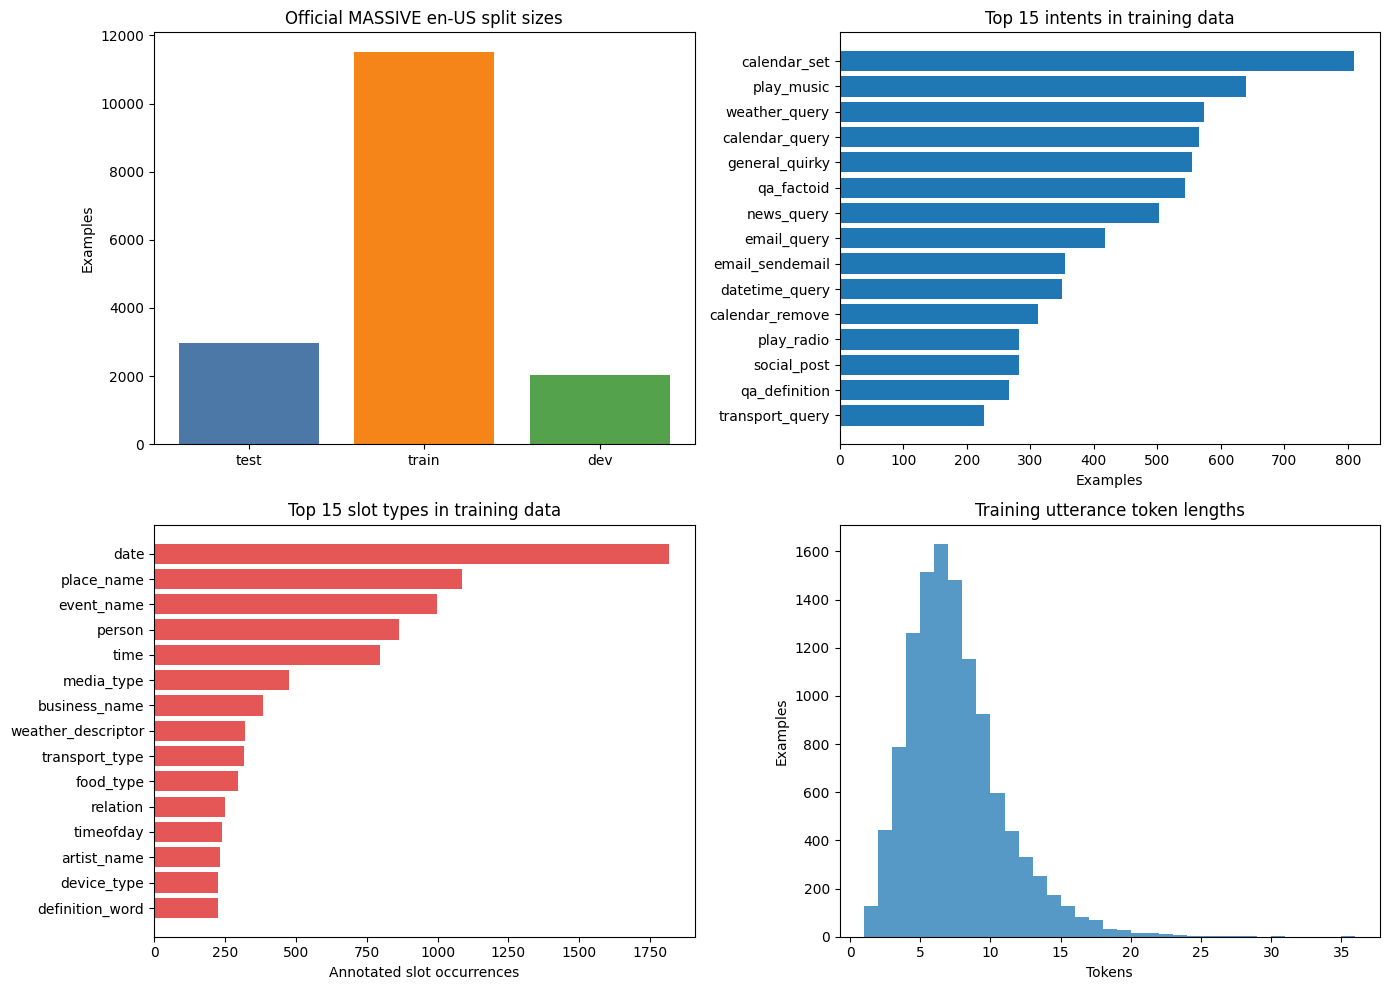

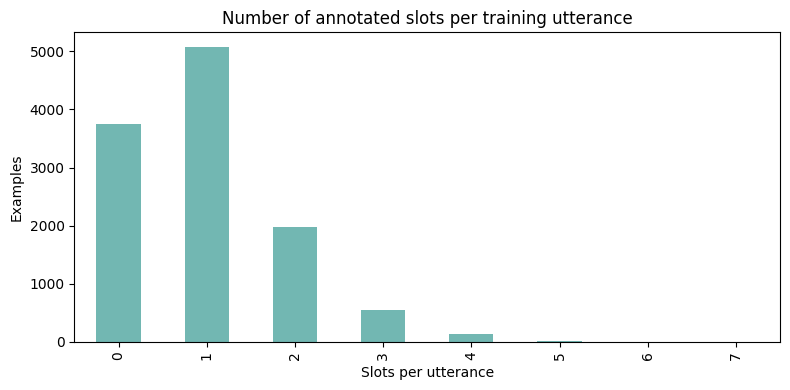

Observation: the long-tailed intent and slot distributions motivate micro-F1 reporting, while dynamic padding and packed sequences avoid work on the many short utterances. Offset-preserving tokenization is necessary for multi-word and punctuation-adjacent slots.


In [3]:
SLOT_PATTERN = re.compile(r"\[([A-Za-z0-9_]+)\s*:\s*(.*?)\]")
TOKEN_PATTERN = re.compile(r"\w+(?:['’]\w+)*|[^\w\s]", flags=re.UNICODE)


def parse_slot_annotations(record_or_utt, annot_utt: str | None = None):
    """Parse MASSIVE bracket annotations into exact character spans.

    Returns the reconstructed plain utterance and an occurrence-preserving list
    of dictionaries with type, start, end, and text. Any mismatch is fatal.
    """
    if isinstance(record_or_utt, dict):
        utt = record_or_utt["utt"]
        annotated = record_or_utt["annot_utt"]
        record_id = record_or_utt.get("id", "unknown")
    else:
        utt = record_or_utt
        annotated = annot_utt
        record_id = "manual"
    if annotated is None:
        raise ValueError("annot_utt is required")
    parts, spans = [], []
    annotated_cursor = 0
    plain_cursor = 0
    for match in SLOT_PATTERN.finditer(annotated):
        literal = annotated[annotated_cursor:match.start()]
        parts.append(literal)
        plain_cursor += len(literal)
        slot_type = match.group(1)
        slot_text = match.group(2)
        start = plain_cursor
        end = start + len(slot_text)
        parts.append(slot_text)
        spans.append({"type": slot_type, "start": start, "end": end, "text": slot_text})
        plain_cursor = end
        annotated_cursor = match.end()
    tail = annotated[annotated_cursor:]
    parts.append(tail)
    reconstructed = "".join(parts)
    if reconstructed != utt:
        raise ValueError(
            f"Annotation reconstruction failed for record {record_id}:\n"
            f"utt={utt!r}\nannot_utt={annotated!r}\nreconstructed={reconstructed!r}"
        )
    for span in spans:
        assert 0 <= span["start"] < span["end"] <= len(utt)
        assert utt[span["start"]:span["end"]] == span["text"]
    return reconstructed, spans


def tokenize_with_offsets(utterance: str):
    """Deterministic Unicode-aware word/punctuation tokenization with offsets."""
    matches = list(TOKEN_PATTERN.finditer(utterance))
    return [match.group(0) for match in matches], [(match.start(), match.end()) for match in matches]


parsed_all = {record["id"]: parse_slot_annotations(record)[1] for record in all_data}
official_intents = sorted({record["intent"] for record in all_data})
official_slot_types = sorted({span["type"] for spans in parsed_all.values() for span in spans})
assert len(official_intents) == 60
assert len(official_slot_types) == 55

train_intent_counts = Counter(record["intent"] for record in train_data)
train_slot_counts = Counter(
    span["type"] for record in train_data for span in parsed_all[record["id"]]
)
train_lengths = [len(tokenize_with_offsets(record["utt"])[0]) for record in train_data]
train_slot_numbers = [len(parsed_all[record["id"]]) for record in train_data]

print(f"Unique intents in official inventory: {len(official_intents)}")
print(f"Unique slot types in official inventory: {len(official_slot_types)}")
print("Most frequent training intents:", train_intent_counts.most_common(8))
print("Least frequent training intents:", sorted(train_intent_counts.items(), key=lambda pair: pair[1])[:8])
print("Most frequent training slot types:", train_slot_counts.most_common(10))
print("Least frequent training slot types:", sorted(train_slot_counts.items(), key=lambda pair: pair[1])[:10])
print(
    "Training token lengths - "
    f"mean={np.mean(train_lengths):.2f}, median={np.median(train_lengths):.2f}, "
    f"min={min(train_lengths)}, max={max(train_lengths)}"
)
no_slot_percentage = 100.0 * sum(count == 0 for count in train_slot_numbers) / len(train_slot_numbers)
print(f"Training examples with no slots: {no_slot_percentage:.2f}%")

multi_slot_examples = [record for record in train_data if len(parsed_all[record["id"]]) >= 2][:3]
multiword_examples = [
    record for record in train_data
    if any(" " in span["text"] for span in parsed_all[record["id"]])
][:3]
punctuation_examples = [
    record for record in train_data
    if re.search(r"[^\w\s']", record["utt"])
][:3]
print("\nMultiple-slot examples:")
for example in multi_slot_examples:
    print(" -", example["annot_utt"])
print("\nMulti-word slot examples:")
for example in multiword_examples:
    print(" -", example["annot_utt"])
print("\nPunctuation-sensitive examples:")
for example in punctuation_examples:
    print(" -", example["annot_utt"])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].bar(partition_counts.keys(), partition_counts.values(), color=["#4C78A8", "#F58518", "#54A24B"])
axes[0, 0].set_title("Official MASSIVE en-US split sizes")
axes[0, 0].set_ylabel("Examples")

top_intents = train_intent_counts.most_common(15)
axes[0, 1].barh([name for name, _ in reversed(top_intents)], [count for _, count in reversed(top_intents)])
axes[0, 1].set_title("Top 15 intents in training data")
axes[0, 1].set_xlabel("Examples")

top_slots = train_slot_counts.most_common(15)
axes[1, 0].barh([name for name, _ in reversed(top_slots)], [count for _, count in reversed(top_slots)], color="#E45756")
axes[1, 0].set_title("Top 15 slot types in training data")
axes[1, 0].set_xlabel("Annotated slot occurrences")

axes[1, 1].hist(train_lengths, bins=range(1, max(train_lengths) + 2), alpha=0.75, label="token length")
axes[1, 1].set_title("Training utterance token lengths")
axes[1, 1].set_xlabel("Tokens")
axes[1, 1].set_ylabel("Examples")
plt.tight_layout()
plt.show()

slot_number_series = pd.Series(train_slot_numbers).value_counts().sort_index()
ax = slot_number_series.plot(kind="bar", figsize=(8, 4), color="#72B7B2")
ax.set_title("Number of annotated slots per training utterance")
ax.set_xlabel("Slots per utterance")
ax.set_ylabel("Examples")
plt.tight_layout()
plt.show()

print(
    "Observation: the long-tailed intent and slot distributions motivate micro-F1 reporting, "
    "while dynamic padding and packed sequences avoid work on the many short utterances. "
    "Offset-preserving tokenization is necessary for multi-word and punctuation-adjacent slots."
)

## 4. Offset-preserving preprocessing, BIO supervision, and character features

The exact annotation parser and offset-preserving tokenizer are unchanged from the baseline. Vocabulary statistics and character vocabulary are fitted on training examples only. Character IDs provide trainable morphology for unseen words while preserving the original token/character offsets used by exact-span evaluation.

Each gold BIO label is also factorized into a boundary target (`O`, `B`, or `I`) and a slot-type target. Slot type is ignored on `O` tokens. Decoding later recombines the structured boundary path and one aggregated type decision per complete span into the original 111-label BIO space.

In [4]:
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
PAD_ID = 0
UNK_ID = 1
SLOT_PAD_ID = -100
CHAR_PAD_TOKEN = "<CPAD>"
CHAR_UNK_TOKEN = "<CUNK>"
CHAR_PAD_ID = 0
CHAR_UNK_ID = 1
BOUNDARY_TO_ID = {"O": 0, "B": 1, "I": 2}
ID_TO_BOUNDARY = {index: label for label, index in BOUNDARY_TO_ID.items()}


def spans_to_bio(utterance: str, offsets, spans):
    """Align exact character spans to tokens and return BIO strings."""
    labels = ["O"] * len(offsets)
    for span in spans:
        token_indices = [
            index for index, (start, end) in enumerate(offsets)
            if start >= span["start"] and end <= span["end"]
        ]
        if not token_indices:
            raise ValueError(f"No token aligned to slot span {span} in {utterance!r}")
        first, last = token_indices[0], token_indices[-1]
        if offsets[first][0] != span["start"] or offsets[last][1] != span["end"]:
            raise ValueError(
                f"Slot boundary is not a token boundary: span={span}, "
                f"tokens={[(utterance[s:e], s, e) for s, e in offsets]}"
            )
        if any(labels[index] != "O" for index in token_indices):
            raise ValueError(f"Overlapping slot annotations are unsupported: {spans}")
        labels[first] = f"B-{span['type']}"
        for index in token_indices[1:]:
            labels[index] = f"I-{span['type']}"
    return labels


def prepare_record(record):
    _, spans = parse_slot_annotations(record)
    tokens, offsets = tokenize_with_offsets(record["utt"])
    if not tokens:
        raise ValueError(f"Record {record.get('id')} produced no tokens")
    bio_labels = spans_to_bio(record["utt"], offsets, spans)
    return {
        "id": record["id"],
        "partition": record["partition"],
        "utt": record["utt"],
        "intent": record["intent"],
        "tokens": tokens,
        "offsets": offsets,
        "bio_labels": bio_labels,
        "gold_spans": [(span["type"], span["start"], span["end"]) for span in spans],
    }


prepared_all = [prepare_record(record) for record in all_data]
prepared_by_id = {example["id"]: example for example in prepared_all}
prepared_train = [prepared_by_id[record["id"]] for record in train_data]
prepared_dev = [prepared_by_id[record["id"]] for record in dev_data]
prepared_test = [prepared_by_id[record["id"]] for record in test_data]
assert len(prepared_all) == len(all_data)
assert len(prepared_train) == 11514 and len(prepared_dev) == 2033 and len(prepared_test) == 2974


def build_vocabulary(training_examples, min_frequency=1, max_size=None):
    counts = Counter(token for example in training_examples for token in example["tokens"])
    ordered = sorted(counts.items(), key=lambda pair: (-pair[1], pair[0]))
    ordered = [pair for pair in ordered if pair[1] >= min_frequency]
    if max_size is not None:
        ordered = ordered[: max(0, max_size - 2)]
    vocabulary = {PAD_TOKEN: PAD_ID, UNK_TOKEN: UNK_ID}
    vocabulary.update({token: index + 2 for index, (token, _) in enumerate(ordered)})
    return vocabulary, counts


vocab, train_token_counts = build_vocabulary(
    prepared_train,
    CONFIG["min_token_frequency"],
    CONFIG["max_vocab_size"],
)
intent_to_id = {label: index for index, label in enumerate(official_intents)}
id_to_intent = {index: label for label, index in intent_to_id.items()}
bio_labels = ["O"] + [prefix + slot for slot in official_slot_types for prefix in ("B-", "I-")]
bio_to_id = {label: index for index, label in enumerate(bio_labels)}
id_to_bio = {index: label for label, index in bio_to_id.items()}
assert len(intent_to_id) == 60
assert len(bio_to_id) == 111

char_inventory = sorted({character for example in prepared_train for token in example["tokens"] for character in token})
char_vocab = {CHAR_PAD_TOKEN: CHAR_PAD_ID, CHAR_UNK_TOKEN: CHAR_UNK_ID}
char_vocab.update({character: index + 2 for index, character in enumerate(char_inventory)})
slot_type_to_id = {label: index for index, label in enumerate(official_slot_types)}
id_to_slot_type = {index: label for label, index in slot_type_to_id.items()}


def encode_example(example):
    encoded = dict(example)
    encoded["word_ids"] = [vocab.get(token, UNK_ID) for token in example["tokens"]]
    encoded["length"] = len(encoded["word_ids"])
    encoded["intent_id"] = intent_to_id[example["intent"]]
    encoded["bio_ids"] = [bio_to_id[label] for label in example["bio_labels"]]
    encoded["char_ids"] = [
        [char_vocab.get(character, CHAR_UNK_ID) for character in token]
        for token in example["tokens"]
    ]
    encoded["boundary_ids"] = []
    encoded["slot_type_ids"] = []
    for label in example["bio_labels"]:
        if label == "O":
            encoded["boundary_ids"].append(BOUNDARY_TO_ID["O"])
            encoded["slot_type_ids"].append(SLOT_PAD_ID)
        else:
            prefix, slot_type = label.split("-", 1)
            encoded["boundary_ids"].append(BOUNDARY_TO_ID[prefix])
            encoded["slot_type_ids"].append(slot_type_to_id[slot_type])
    return encoded


encoded_train = [encode_example(example) for example in prepared_train]
encoded_dev = [encode_example(example) for example in prepared_dev]
encoded_test = [encode_example(example) for example in prepared_test]

print(f"Training vocabulary size (including specials): {len(vocab):,}")
print(f"Training character vocabulary size (including specials): {len(char_vocab):,}")
for name, examples in (("train", encoded_train), ("dev", encoded_dev), ("test", encoded_test)):
    token_total = sum(example["length"] for example in examples)
    unk_total = sum(token_id == UNK_ID for example in examples for token_id in example["word_ids"])
    print(f"{name:>5} UNK rate: {100.0 * unk_total / token_total:.2f}% ({unk_total:,}/{token_total:,})")

# Essential corpus-wide alignment checks: decode of gold BIO must be exact.
def decode_bio_spans(bio_sequence, offsets, utterance):
    """Decode BIO tags to occurrence-aware (type, start, end) spans.

    Invalid I-X transitions are repaired deterministically as B-X. This policy is
    applied identically to gold checks and predictions.
    """
    decoded = []
    active_type = None
    active_start = None
    active_end = None

    def close_active():
        nonlocal active_type, active_start, active_end
        if active_type is not None:
            decoded.append((active_type, active_start, active_end))
        active_type = active_start = active_end = None

    for label, (start, end) in zip(bio_sequence, offsets):
        if label == "O":
            close_active()
            continue
        if "-" not in label:
            raise ValueError(f"Malformed BIO label: {label!r}")
        prefix, slot_type = label.split("-", 1)
        if prefix == "B":
            close_active()
            active_type, active_start, active_end = slot_type, start, end
        elif prefix == "I":
            if active_type == slot_type:
                active_end = end
            else:
                close_active()  # invalid I transition becomes a new B span
                active_type, active_start, active_end = slot_type, start, end
        else:
            raise ValueError(f"Malformed BIO prefix: {prefix!r}")
    close_active()
    for slot_type, start, end in decoded:
        assert 0 <= start < end <= len(utterance)
    return decoded


for example in prepared_all:
    decoded_gold = decode_bio_spans(example["bio_labels"], example["offsets"], example["utt"])
    if Counter(decoded_gold) != Counter(example["gold_spans"]):
        raise AssertionError(
            f"Gold BIO round-trip failed for {example['id']}: "
            f"expected={example['gold_spans']}, decoded={decoded_gold}"
        )
print(f"Passed reconstruction, boundary, and gold BIO round-trip checks for all {len(prepared_all):,} examples.")

# Targeted synthetic checks for multi-token spans, punctuation, and repeated words.
synthetic_cases = [
    ("set it for five thirty", [{"type": "time", "start": 11, "end": 22, "text": "five thirty"}]),
    ("play hello, world", [{"type": "song_name", "start": 5, "end": 17, "text": "hello, world"}]),
    ("red then red", [{"type": "color_type", "start": 9, "end": 12, "text": "red"}]),
]
for utterance, spans in synthetic_cases:
    tokens, offsets = tokenize_with_offsets(utterance)
    tags = spans_to_bio(utterance, offsets, spans)
    expected = [(span["type"], span["start"], span["end"]) for span in spans]
    assert decode_bio_spans(tags, offsets, utterance) == expected
print("Passed targeted multi-token, punctuation, and repeated-word alignment tests.")

Training vocabulary size (including specials): 5,294
Training character vocabulary size (including specials): 34
train UNK rate: 0.00% (0/81,120)
  dev UNK rate: 3.27% (464/14,182)
 test UNK rate: 3.46% (712/20,571)
Passed reconstruction, boundary, and gold BIO round-trip checks for all 16,521 examples.
Passed targeted multi-token, punctuation, and repeated-word alignment tests.


## 5. GloVe 6B 300-dimensional initialization

Only vectors needed by the training vocabulary are retained. Exact-token lookup is attempted first, followed by a lowercase lookup. OOV rows use seeded random normal initialization; `<PAD>` is zero. The embedding table remains trainable and counts toward the 20M limit.

In [5]:
GLOVE_URL = "https://nlp.stanford.edu/data/glove.6B.zip"
GLOVE_ARCHIVE = DOWNLOAD_DIR / "glove.6B.zip"
GLOVE_PATH = DATA_DIR / "glove" / "glove.6B.300d.txt"


def ensure_glove_300d() -> Path:
    if GLOVE_PATH.exists():
        print(f"Using existing GloVe file: {GLOVE_PATH}")
        return GLOVE_PATH
    download_file(GLOVE_URL, GLOVE_ARCHIVE)
    member_name = "glove.6B.300d.txt"
    with zipfile.ZipFile(GLOVE_ARCHIVE) as archive:
        if member_name not in archive.namelist():
            raise RuntimeError(f"{member_name!r} is absent from {GLOVE_ARCHIVE}")
        GLOVE_PATH.parent.mkdir(parents=True, exist_ok=True)
        temporary = GLOVE_PATH.with_suffix(".txt.part")
        with archive.open(member_name) as source, temporary.open("wb") as output:
            shutil.copyfileobj(source, output)
        temporary.replace(GLOVE_PATH)
    return GLOVE_PATH


def build_embedding_matrix(vocabulary, glove_path, dimension, seed):
    """Stream GloVe and keep only vectors needed for the training vocabulary."""
    rng = np.random.default_rng(seed)
    matrix = rng.normal(0.0, 0.05, size=(len(vocabulary), dimension)).astype(np.float32)
    matrix[PAD_ID] = 0.0
    exact_needed = set(vocabulary) - {PAD_TOKEN, UNK_TOKEN}
    lowercase_to_tokens = collections.defaultdict(list)
    for token in exact_needed:
        lowercase_to_tokens[token.lower()].append(token)
    found_tokens = set()
    with Path(glove_path).open("r", encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            pieces = line.rstrip().split(" ")
            word, values = pieces[0], pieces[1:]
            if word not in exact_needed and word not in lowercase_to_tokens:
                continue
            if len(values) != dimension:
                raise ValueError(f"GloVe dimension error on line {line_number}")
            vector = np.asarray(values, dtype=np.float32)
            if word in exact_needed and word not in found_tokens:
                matrix[vocabulary[word]] = vector
                found_tokens.add(word)
            for original_token in lowercase_to_tokens.get(word, []):
                if original_token not in found_tokens:
                    matrix[vocabulary[original_token]] = vector
                    found_tokens.add(original_token)
    matchable = len(vocabulary) - 2
    matched = len(found_tokens)
    return matrix, {
        "vocabulary_size": len(vocabulary),
        "embedding_dimension": dimension,
        "matched_tokens": matched,
        "unmatched_tokens": matchable - matched,
        "coverage_percent": 100.0 * matched / matchable if matchable else 0.0,
        "source": "GloVe 6B 300d",
        "fine_tuned": CONFIG["fine_tune_embeddings"],
    }


glove_path = ensure_glove_300d()
embedding_matrix, embedding_info = build_embedding_matrix(
    vocab, glove_path, CONFIG["embedding_dim"], CONFIG["seed"]
)
print(json.dumps(embedding_info, indent=2))

Using existing GloVe file: C:\Users\envy\OneDrive\Documents\Desktop\NLP\data\glove\glove.6B.300d.txt


{
  "vocabulary_size": 5294,
  "embedding_dimension": 300,
  "matched_tokens": 4914,
  "unmatched_tokens": 378,
  "coverage_percent": 92.85714285714286,
  "source": "GloVe 6B 300d",
  "fine_tuned": true
}


## 6. Shared exact-span evaluation functions

Slot evaluation uses occurrence-aware `(slot_type, character_start, character_end)` tuples and `Counter` intersections. Thus identical text at different offsets is distinct, duplicate occurrences are retained, and partial boundaries never match. If an evaluated collection has no gold or predicted slots at all, its slot F1 is defined as 100% (perfect empty prediction); any false positive makes it 0%.

In [6]:
def compute_intent_accuracy(predicted_ids, gold_ids):
    if len(predicted_ids) != len(gold_ids) or not gold_ids:
        raise ValueError("Intent predictions and gold labels must have equal non-zero length")
    return 100.0 * sum(pred == gold for pred, gold in zip(predicted_ids, gold_ids)) / len(gold_ids)


def slot_counts(predicted_spans_by_example, gold_spans_by_example):
    if len(predicted_spans_by_example) != len(gold_spans_by_example):
        raise ValueError("Predicted and gold slot collections must have equal length")
    true_positive = false_positive = false_negative = 0
    for predicted, gold in zip(predicted_spans_by_example, gold_spans_by_example):
        predicted_counter = Counter(map(tuple, predicted))
        gold_counter = Counter(map(tuple, gold))
        matches = sum((predicted_counter & gold_counter).values())
        true_positive += matches
        false_positive += sum(predicted_counter.values()) - matches
        false_negative += sum(gold_counter.values()) - matches
    return true_positive, false_positive, false_negative


def compute_slot_micro_f1(predicted_spans_by_example, gold_spans_by_example):
    tp, fp, fn = slot_counts(predicted_spans_by_example, gold_spans_by_example)
    denominator = 2 * tp + fp + fn
    return 100.0 if denominator == 0 else 100.0 * (2 * tp) / denominator


def compute_combined_score(intent_accuracy, slot_micro_f1):
    return (intent_accuracy + slot_micro_f1) / 2.0


# Hand-constructed metric unit tests.
assert compute_intent_accuracy([1], [1]) == 100.0
assert compute_intent_accuracy([1, 0], [1, 1]) == 50.0
exact = [[("time", 3, 10)]]
assert compute_slot_micro_f1(exact, exact) == 100.0
assert compute_slot_micro_f1([[("time", 3, 9)]], exact) == 0.0  # wrong boundary
assert compute_slot_micro_f1([[('date', 3, 10)]], exact) == 0.0  # wrong type
assert math.isclose(
    compute_slot_micro_f1([[('time', 3, 10), ('date', 12, 18)]], exact), 200 / 3
)
assert compute_slot_micro_f1([[]], [[]]) == 100.0
assert compute_slot_micro_f1([[('time', 0, 2)]], [[]]) == 0.0
duplicate_gold = [[("color", 0, 3), ("color", 8, 11)]]
assert compute_slot_micro_f1(duplicate_gold, duplicate_gold) == 100.0
assert math.isclose(compute_slot_micro_f1([[('color', 0, 3)]], duplicate_gold), 200 / 3)

# Invalid I transitions are deterministically repaired as a B of the same type.
invalid_i = decode_bio_spans(["I-color", "I-color"], [(0, 3), (4, 7)], "red red")
assert invalid_i == [("color", 0, 7)]
switched_i = decode_bio_spans(["B-time", "I-date"], [(0, 3), (4, 7)], "one day")
assert switched_i == [("time", 0, 3), ("date", 4, 7)]
print("All intent, exact-span slot, empty-case, duplicate-occurrence, and invalid-BIO tests passed.")

All intent, exact-span slot, empty-case, duplicate-occurrence, and invalid-BIO tests passed.


## 7. Enhanced joint architecture

The shared representation is built from fine-tuned GloVe 300D vectors and trainable character-CNN features, then encoded by a two-layer bidirectional LSTM. Intent classification concatenates masked attention, mean, and max pooling. The predicted intent distribution produces a differentiable intent context that is concatenated to every token representation for slot prediction.

Slot prediction is factorized into three boundary states and 55 slot types. A small constrained CRF models boundary transitions, while type logits are averaged across each decoded span so one span cannot change type internally. Both tasks remain in one model with one shared encoder.

In [7]:
class MassiveJointDataset(Dataset):
    def __init__(self, encoded_examples):
        self.examples = encoded_examples

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        return self.examples[index]


def collate_batch(examples):
    batch_size = len(examples)
    max_length = max(example["length"] for example in examples)
    max_word_length = max(
        max(len(characters), 1)
        for example in examples for characters in example["char_ids"]
    )
    input_ids = torch.full((batch_size, max_length), PAD_ID, dtype=torch.long)
    char_ids = torch.full(
        (batch_size, max_length, max_word_length), CHAR_PAD_ID, dtype=torch.long
    )
    bio_ids = torch.full((batch_size, max_length), SLOT_PAD_ID, dtype=torch.long)
    boundary_ids = torch.full((batch_size, max_length), SLOT_PAD_ID, dtype=torch.long)
    slot_type_ids = torch.full((batch_size, max_length), SLOT_PAD_ID, dtype=torch.long)
    lengths = torch.tensor([example["length"] for example in examples], dtype=torch.long)
    intent_ids = torch.tensor([example["intent_id"] for example in examples], dtype=torch.long)
    for row, example in enumerate(examples):
        length = example["length"]
        input_ids[row, :length] = torch.tensor(example["word_ids"], dtype=torch.long)
        bio_ids[row, :length] = torch.tensor(example["bio_ids"], dtype=torch.long)
        boundary_ids[row, :length] = torch.tensor(example["boundary_ids"], dtype=torch.long)
        slot_type_ids[row, :length] = torch.tensor(example["slot_type_ids"], dtype=torch.long)
        for column, characters in enumerate(example["char_ids"]):
            if characters:
                char_ids[row, column, :len(characters)] = torch.tensor(characters, dtype=torch.long)
    attention_mask = input_ids.ne(PAD_ID)
    return {
        "input_ids": input_ids,
        "char_ids": char_ids,
        "bio_ids": bio_ids,
        "boundary_ids": boundary_ids,
        "slot_type_ids": slot_type_ids,
        "lengths": lengths,
        "intent_ids": intent_ids,
        "attention_mask": attention_mask,
        "examples": examples,
    }


train_generator = torch.Generator().manual_seed(CONFIG["seed"])
train_loader = DataLoader(
    MassiveJointDataset(encoded_train), batch_size=CONFIG["batch_size"], shuffle=True,
    num_workers=CONFIG["num_workers"], collate_fn=collate_batch, generator=train_generator,
)
dev_loader = DataLoader(
    MassiveJointDataset(encoded_dev), batch_size=CONFIG["batch_size"], shuffle=False,
    num_workers=CONFIG["num_workers"], collate_fn=collate_batch,
)
test_loader = DataLoader(
    MassiveJointDataset(encoded_test), batch_size=CONFIG["batch_size"], shuffle=False,
    num_workers=CONFIG["num_workers"], collate_fn=collate_batch,
)


class BoundaryCRF(nn.Module):
    """Three-state linear-chain CRF with BIO-valid transitions."""
    def __init__(self):
        super().__init__()
        self.transitions = nn.Parameter(torch.empty(3, 3))  # previous -> current
        self.start_transitions = nn.Parameter(torch.empty(3))
        self.end_transitions = nn.Parameter(torch.empty(3))
        allowed = torch.tensor(
            [
                [True, True, False],   # O -> O/B
                [True, True, True],    # B -> O/B/I
                [True, True, True],    # I -> O/B/I
            ],
            dtype=torch.bool,
        )
        self.register_buffer("allowed_transitions", allowed)
        self.register_buffer("allowed_starts", torch.tensor([True, True, False]))
        self.reset_parameters()

    def reset_parameters(self):
        nn.init.uniform_(self.transitions, -0.1, 0.1)
        nn.init.uniform_(self.start_transitions, -0.1, 0.1)
        nn.init.uniform_(self.end_transitions, -0.1, 0.1)

    def constrained_transitions(self):
        return self.transitions.masked_fill(~self.allowed_transitions, -10000.0)

    def constrained_starts(self):
        return self.start_transitions.masked_fill(~self.allowed_starts, -10000.0)

    def log_partition(self, emissions, mask):
        transitions = self.constrained_transitions()
        score = self.constrained_starts() + emissions[:, 0]
        for step in range(1, emissions.size(1)):
            candidates = (
                score.unsqueeze(2)
                + transitions.unsqueeze(0)
                + emissions[:, step].unsqueeze(1)
            )
            next_score = torch.logsumexp(candidates, dim=1)
            score = torch.where(mask[:, step].unsqueeze(1), next_score, score)
        return torch.logsumexp(score + self.end_transitions, dim=1)

    def gold_score(self, emissions, tags, mask):
        safe_tags = tags.masked_fill(~mask, 0)
        batch_indices = torch.arange(emissions.size(0), device=emissions.device)
        score = self.constrained_starts()[safe_tags[:, 0]]
        score = score + emissions[batch_indices, 0, safe_tags[:, 0]]
        transitions = self.constrained_transitions()
        for step in range(1, emissions.size(1)):
            step_score = transitions[safe_tags[:, step - 1], safe_tags[:, step]]
            step_score = step_score + emissions[batch_indices, step, safe_tags[:, step]]
            score = score + torch.where(mask[:, step], step_score, torch.zeros_like(step_score))
        last_positions = mask.long().sum(dim=1) - 1
        last_tags = safe_tags.gather(1, last_positions.unsqueeze(1)).squeeze(1)
        return score + self.end_transitions[last_tags]

    def neg_log_likelihood(self, emissions, tags, mask):
        return (self.log_partition(emissions, mask) - self.gold_score(emissions, tags, mask)).mean()

    def decode(self, emissions, mask):
        transitions = self.constrained_transitions()
        paths = []
        for row in range(emissions.size(0)):
            length = int(mask[row].sum().item())
            score = self.constrained_starts() + emissions[row, 0]
            history = []
            for step in range(1, length):
                candidates = score.unsqueeze(1) + transitions
                best_score, best_previous = candidates.max(dim=0)
                score = best_score + emissions[row, step]
                history.append(best_previous)
            best_last = int((score + self.end_transitions).argmax().item())
            path = [best_last]
            for best_previous in reversed(history):
                path.append(int(best_previous[path[-1]].item()))
            paths.append(list(reversed(path)))
        return paths


class CharacterCNN(nn.Module):
    def __init__(self, vocabulary_size, embedding_dim, channels, kernels):
        super().__init__()
        self.embedding = nn.Embedding(vocabulary_size, embedding_dim, padding_idx=CHAR_PAD_ID)
        self.convolutions = nn.ModuleList([
            nn.Conv1d(embedding_dim, channels, kernel_size, padding=kernel_size // 2, bias=False)
            for kernel_size in kernels
        ])
        self.output_dim = channels * len(kernels)

    def forward(self, character_ids):
        batch_size, token_count, character_count = character_ids.shape
        embedded = self.embedding(character_ids.reshape(batch_size * token_count, character_count))
        embedded = embedded.transpose(1, 2)
        features = [torch.relu(convolution(embedded)).amax(dim=-1) for convolution in self.convolutions]
        return torch.cat(features, dim=-1).reshape(batch_size, token_count, self.output_dim)


class JointBiLSTM(nn.Module):
    """Enhanced shared BiLSTM with character features and structured slot decoding."""
    def __init__(
        self, vocab_size, char_vocab_size, embedding_dim, hidden_dim, num_layers,
        dropout, num_intents, num_slot_types, pretrained_embeddings=None,
        fine_tune_embeddings=True,
    ):
        super().__init__()
        self.word_dropout_probability = CONFIG["word_dropout"]
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_ID)
        if pretrained_embeddings is not None:
            tensor = torch.as_tensor(pretrained_embeddings, dtype=torch.float32)
            if tuple(tensor.shape) != (vocab_size, embedding_dim):
                raise ValueError(f"Unexpected embedding shape: {tuple(tensor.shape)}")
            with torch.no_grad():
                self.embedding.weight.copy_(tensor)
        self.embedding.weight.requires_grad = fine_tune_embeddings
        self.character_encoder = CharacterCNN(
            char_vocab_size, CONFIG["char_embedding_dim"],
            CONFIG["char_channels"], CONFIG["char_kernels"],
        )
        encoder_input_dim = embedding_dim + self.character_encoder.output_dim
        self.input_normalization = nn.LayerNorm(encoder_input_dim)
        self.embedding_dropout = nn.Dropout(dropout)
        self.encoder = nn.LSTM(
            input_size=encoder_input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        encoder_dim = 2 * hidden_dim
        self.output_normalization = nn.LayerNorm(encoder_dim)
        self.output_dropout = nn.Dropout(dropout)
        self.attention = nn.Sequential(
            nn.Linear(encoder_dim, CONFIG["attention_dim"]),
            nn.Tanh(),
            nn.Linear(CONFIG["attention_dim"], 1, bias=False),
        )
        pooled_dim = 3 * encoder_dim
        self.intent_head = nn.Sequential(
            nn.Linear(pooled_dim, CONFIG["intent_hidden_dim"]),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(CONFIG["intent_hidden_dim"], num_intents),
        )
        self.intent_label_embeddings = nn.Embedding(num_intents, CONFIG["intent_context_dim"])
        slot_input_dim = encoder_dim + CONFIG["intent_context_dim"]
        self.slot_shared = nn.Sequential(
            nn.Linear(slot_input_dim, CONFIG["slot_hidden_dim"]),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.boundary_head = nn.Linear(CONFIG["slot_hidden_dim"], 3)
        self.slot_head = nn.Linear(CONFIG["slot_hidden_dim"], num_slot_types)
        self.boundary_crf = BoundaryCRF()

    def apply_word_dropout(self, input_ids):
        if not self.training or self.word_dropout_probability <= 0:
            return input_ids
        drop_mask = (
            torch.rand(input_ids.shape, device=input_ids.device) < self.word_dropout_probability
        ) & input_ids.ne(PAD_ID)
        return input_ids.masked_fill(drop_mask, UNK_ID)

    def forward(self, input_ids, char_ids, lengths, attention_mask):
        word_ids = self.apply_word_dropout(input_ids)
        word_features = self.embedding(word_ids)
        character_features = self.character_encoder(char_ids)
        embedded = torch.cat([word_features, character_features], dim=-1)
        embedded = self.embedding_dropout(self.input_normalization(embedded))
        packed = pack_padded_sequence(
            embedded, lengths.detach().cpu(), batch_first=True, enforce_sorted=False
        )
        packed_output, _ = self.encoder(packed)
        encoded, _ = pad_packed_sequence(
            packed_output, batch_first=True, total_length=input_ids.size(1)
        )
        encoded = self.output_dropout(self.output_normalization(encoded))
        mask = attention_mask.unsqueeze(-1)
        float_mask = mask.to(encoded.dtype)
        mean_pool = (encoded * float_mask).sum(dim=1) / float_mask.sum(dim=1).clamp_min(1.0)
        max_pool = encoded.masked_fill(~mask, -1e4).amax(dim=1)
        attention_scores = self.attention(encoded).squeeze(-1).masked_fill(~attention_mask, -1e4)
        attention_weights = torch.softmax(attention_scores, dim=1)
        attention_pool = torch.bmm(attention_weights.unsqueeze(1), encoded).squeeze(1)
        pooled = torch.cat([attention_pool, mean_pool, max_pool], dim=-1)
        intent_logits = self.intent_head(pooled)
        intent_probabilities = torch.softmax(intent_logits, dim=-1)
        intent_context = intent_probabilities @ self.intent_label_embeddings.weight
        expanded_context = intent_context.unsqueeze(1).expand(-1, encoded.size(1), -1)
        slot_features = self.slot_shared(torch.cat([encoded, expanded_context], dim=-1))
        slot_outputs = {
            "boundary_emissions": self.boundary_head(slot_features),
            "type_logits": self.slot_head(slot_features),
        }
        return intent_logits, slot_outputs

    def decode_bio_ids(self, slot_outputs, attention_mask):
        boundary_paths = self.boundary_crf.decode(
            slot_outputs["boundary_emissions"], attention_mask
        )
        type_logits = slot_outputs["type_logits"]
        decoded = []
        for row, path in enumerate(boundary_paths):
            bio_path = [bio_to_id["O"]] * len(path)
            position = 0
            while position < len(path):
                if path[position] != BOUNDARY_TO_ID["B"]:
                    position += 1
                    continue
                end = position + 1
                while end < len(path) and path[end] == BOUNDARY_TO_ID["I"]:
                    end += 1
                slot_type_id = int(type_logits[row, position:end].mean(dim=0).argmax().item())
                slot_type = id_to_slot_type[slot_type_id]
                bio_path[position] = bio_to_id[f"B-{slot_type}"]
                for token_index in range(position + 1, end):
                    bio_path[token_index] = bio_to_id[f"I-{slot_type}"]
                position = end
            decoded.append(bio_path)
        return decoded


def make_model(pretrained=True):
    return JointBiLSTM(
        vocab_size=len(vocab),
        char_vocab_size=len(char_vocab),
        embedding_dim=CONFIG["embedding_dim"],
        hidden_dim=CONFIG["hidden_dim"],
        num_layers=CONFIG["num_layers"],
        dropout=CONFIG["dropout"],
        num_intents=len(intent_to_id),
        num_slot_types=len(slot_type_to_id),
        pretrained_embeddings=embedding_matrix if pretrained else None,
        fine_tune_embeddings=CONFIG["fine_tune_embeddings"],
    )


def parameter_report(model):
    groups = {
        "Word embeddings": sum(parameter.numel() for parameter in model.embedding.parameters()),
        "Character CNN": sum(parameter.numel() for parameter in model.character_encoder.parameters()),
        "Shared BiLSTM": sum(parameter.numel() for parameter in model.encoder.parameters()),
        "Intent pooling/head": sum(parameter.numel() for parameter in model.attention.parameters())
            + sum(parameter.numel() for parameter in model.intent_head.parameters()),
        "Intent-slot context": sum(parameter.numel() for parameter in model.intent_label_embeddings.parameters()),
        "Structured slot head": sum(parameter.numel() for parameter in model.slot_shared.parameters())
            + sum(parameter.numel() for parameter in model.boundary_head.parameters())
            + sum(parameter.numel() for parameter in model.slot_head.parameters())
            + sum(parameter.numel() for parameter in model.boundary_crf.parameters()),
        "Layer norms": sum(parameter.numel() for parameter in model.input_normalization.parameters())
            + sum(parameter.numel() for parameter in model.output_normalization.parameters()),
    }
    total = sum(parameter.numel() for parameter in model.parameters())
    trainable = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    for name, count in groups.items():
        print(f"{name:>22}: {count:,}")
    print(f"{'Total':>22}: {total:,}")
    print(f"{'Trainable':>22}: {trainable:,}")
    assert total <= 20_000_000, f"Parameter cap exceeded: {total:,}"
    return groups, total, trainable


seed_everything(CONFIG["seed"])
model = make_model(pretrained=True).to(DEVICE)
parameter_groups, total_parameters, trainable_parameters = parameter_report(model)

       Word embeddings: 1,588,200
         Character CNN: 20,288
         Shared BiLSTM: 3,026,944
   Intent pooling/head: 474,684
   Intent-slot context: 3,840
  Structured slot head: 162,633
           Layer norms: 1,924
                 Total: 5,278,513
             Trainable: 5,278,513


## 8. Enhanced joint losses and shared evaluation

Intent loss uses mild label smoothing. Slot loss combines boundary-CRF negative log likelihood with token-level slot-type cross-entropy on gold slot tokens. The total loss weights the structured slot objective by 1.2 because exact-span slot filling is the weaker baseline task. Padding remains excluded from every loss.

In [8]:
intent_criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG["intent_label_smoothing"])
slot_type_criterion = nn.CrossEntropyLoss(ignore_index=SLOT_PAD_ID)


def move_batch_to_device(batch, device):
    return {
        key: value.to(device) if torch.is_tensor(value) else value
        for key, value in batch.items()
    }


def compute_joint_loss(model, intent_logits, slot_outputs, batch):
    intent_loss = intent_criterion(intent_logits, batch["intent_ids"])
    boundary_loss = model.boundary_crf.neg_log_likelihood(
        slot_outputs["boundary_emissions"], batch["boundary_ids"], batch["attention_mask"]
    )
    flattened_types = batch["slot_type_ids"].reshape(-1)
    flattened_logits = slot_outputs["type_logits"].reshape(
        -1, slot_outputs["type_logits"].size(-1)
    )
    valid_types = flattened_types.ne(SLOT_PAD_ID)
    type_loss = (
        slot_type_criterion(flattened_logits[valid_types], flattened_types[valid_types])
        if valid_types.any()
        else flattened_logits.sum() * 0.0
    )
    slot_loss = boundary_loss + CONFIG["slot_type_loss_weight"] * type_loss
    total_loss = intent_loss + CONFIG["slot_loss_weight"] * slot_loss
    return total_loss, intent_loss, slot_loss


def train_one_epoch(model, loader, optimizer, device, gradient_clip_norm):
    model.train()
    sums = Counter()
    batch_count = 0
    for raw_batch in loader:
        batch = move_batch_to_device(raw_batch, device)
        optimizer.zero_grad(set_to_none=True)
        intent_logits, slot_outputs = model(
            batch["input_ids"], batch["char_ids"], batch["lengths"], batch["attention_mask"]
        )
        total_loss, intent_loss, slot_loss = compute_joint_loss(
            model, intent_logits, slot_outputs, batch
        )
        if not torch.isfinite(total_loss):
            raise FloatingPointError(f"Non-finite training loss: {total_loss.item()}")
        total_loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), gradient_clip_norm)
        optimizer.step()
        sums.update({
            "total_loss": total_loss.item(),
            "intent_loss": intent_loss.item(),
            "slot_loss": slot_loss.item(),
        })
        batch_count += 1
    return {key: value / batch_count for key, value in sums.items()}


def evaluate_model(model, loader, device, return_predictions=False):
    model.eval()
    sums = Counter()
    batch_count = 0
    predicted_intents, gold_intents = [], []
    predicted_spans, gold_spans = [], []
    ordered_examples = []
    with torch.inference_mode():
        for raw_batch in loader:
            batch = move_batch_to_device(raw_batch, device)
            intent_logits, slot_outputs = model(
                batch["input_ids"], batch["char_ids"], batch["lengths"], batch["attention_mask"]
            )
            total_loss, intent_loss, slot_loss = compute_joint_loss(
                model, intent_logits, slot_outputs, batch
            )
            sums.update({
                "total_loss": total_loss.item(),
                "intent_loss": intent_loss.item(),
                "slot_loss": slot_loss.item(),
            })
            batch_count += 1
            intent_predictions = intent_logits.argmax(dim=-1).cpu().tolist()
            bio_predictions = model.decode_bio_ids(slot_outputs, batch["attention_mask"])
            predicted_intents.extend(intent_predictions)
            gold_intents.extend(raw_batch["intent_ids"].tolist())
            for row, example in enumerate(raw_batch["examples"]):
                length = example["length"]
                labels = [id_to_bio[index] for index in bio_predictions[row][:length]]
                spans = decode_bio_spans(labels, example["offsets"], example["utt"])
                predicted_spans.append(spans)
                gold_spans.append(example["gold_spans"])
                ordered_examples.append(example)
    intent_accuracy = compute_intent_accuracy(predicted_intents, gold_intents)
    slot_micro_f1 = compute_slot_micro_f1(predicted_spans, gold_spans)
    result = {
        "total_loss": sums["total_loss"] / batch_count,
        "intent_loss": sums["intent_loss"] / batch_count,
        "slot_loss": sums["slot_loss"] / batch_count,
        "intent_accuracy": intent_accuracy,
        "slot_micro_f1": slot_micro_f1,
        "combined_score": compute_combined_score(intent_accuracy, slot_micro_f1),
    }
    if return_predictions:
        result["predicted_intents"] = predicted_intents
        result["gold_intents"] = gold_intents
        result["predicted_spans"] = predicted_spans
        result["gold_spans"] = gold_spans
        result["examples"] = ordered_examples
    return result

## 9. CPU diagnostics and one-epoch benchmark

A forward/backward check validates intent, boundary, and slot-type shapes. A training-only batch must overfit before the official run. A disposable full epoch measures the stronger model's CPU cost; every diagnostic model is discarded and the seed is reset before official training.

In [9]:
first_raw_batch = next(iter(train_loader))
first_batch = move_batch_to_device(first_raw_batch, DEVICE)
diagnostic_model = make_model(pretrained=True).to(DEVICE)
diagnostic_model.train()
intent_logits, slot_outputs = diagnostic_model(
    first_batch["input_ids"], first_batch["char_ids"],
    first_batch["lengths"], first_batch["attention_mask"]
)
assert intent_logits.shape == (len(first_raw_batch["examples"]), len(intent_to_id))
assert slot_outputs["boundary_emissions"].shape == (
    len(first_raw_batch["examples"]), first_raw_batch["input_ids"].shape[1], 3
)
assert slot_outputs["type_logits"].shape == (
    len(first_raw_batch["examples"]), first_raw_batch["input_ids"].shape[1], len(slot_type_to_id)
)
assert torch.equal(first_raw_batch["attention_mask"].sum(dim=1), first_raw_batch["lengths"])
smoke_total, smoke_intent, smoke_slot = compute_joint_loss(
    diagnostic_model, intent_logits, slot_outputs, first_batch
)
assert all(torch.isfinite(loss) for loss in (smoke_total, smoke_intent, smoke_slot))
smoke_total.backward()
assert any(parameter.grad is not None for parameter in diagnostic_model.parameters())
print(
    f"Forward/backward passed: intent={tuple(intent_logits.shape)}, "
    f"boundary={tuple(slot_outputs['boundary_emissions'].shape)}, "
    f"types={tuple(slot_outputs['type_logits'].shape)}, loss={smoke_total.item():.4f}"
)

diagnostic_model = make_model(pretrained=True).to(DEVICE)
diagnostic_optimizer = torch.optim.AdamW(diagnostic_model.parameters(), lr=3e-3)
diagnostic_losses = []
for step in range(CONFIG["diagnostic_steps"]):
    diagnostic_model.train()
    diagnostic_optimizer.zero_grad(set_to_none=True)
    intent_logits, slot_outputs = diagnostic_model(
        first_batch["input_ids"], first_batch["char_ids"],
        first_batch["lengths"], first_batch["attention_mask"]
    )
    total_loss, _, _ = compute_joint_loss(
        diagnostic_model, intent_logits, slot_outputs, first_batch
    )
    total_loss.backward()
    nn.utils.clip_grad_norm_(diagnostic_model.parameters(), CONFIG["gradient_clip_norm"])
    diagnostic_optimizer.step()
    diagnostic_losses.append(total_loss.item())
assert diagnostic_losses[-1] < diagnostic_losses[0], diagnostic_losses
print(
    f"One-batch overfit diagnostic passed: {diagnostic_losses[0]:.4f} -> "
    f"{diagnostic_losses[-1]:.4f} over {CONFIG['diagnostic_steps']} steps"
)
del diagnostic_model, diagnostic_optimizer, intent_logits, slot_outputs
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

seed_everything(CONFIG["seed"])
benchmark_model = make_model(pretrained=True).to(DEVICE)
benchmark_optimizer = torch.optim.AdamW(
    benchmark_model.parameters(), lr=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"]
)
benchmark_start = time.perf_counter()
benchmark_losses = train_one_epoch(
    benchmark_model, train_loader, benchmark_optimizer, DEVICE, CONFIG["gradient_clip_norm"]
)
benchmark_epoch_seconds = time.perf_counter() - benchmark_start
estimated_official_minutes = benchmark_epoch_seconds * CONFIG["max_epochs"] / 60.0
print(f"Benchmark epoch losses: {benchmark_losses}")
print(f"Measured full training epoch: {benchmark_epoch_seconds:.2f} seconds")
print(
    f"Estimated upper-bound time for {CONFIG['max_epochs']} official epochs: "
    f"{estimated_official_minutes:.1f} minutes (validation overhead excluded)"
)
del benchmark_model, benchmark_optimizer
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

seed_everything(CONFIG["seed"])
train_generator.manual_seed(CONFIG["seed"])
model = make_model(pretrained=True).to(DEVICE)
parameter_groups, total_parameters, trainable_parameters = parameter_report(model)

Forward/backward passed: intent=(32, 60), boundary=(32, 16, 3), types=(32, 16, 55), loss=16.3840


One-batch overfit diagnostic passed: 16.4790 -> 3.1895 over 40 steps


Benchmark epoch losses: {'total_loss': 6.580822379059262, 'intent_loss': 2.6831094480223125, 'slot_loss': 3.2480939861800935}
Measured full training epoch: 173.01 seconds
Estimated upper-bound time for 25 official epochs: 72.1 minutes (validation overhead excluded)


       Word embeddings: 1,588,200
         Character CNN: 20,288
         Shared BiLSTM: 3,026,944
   Intent pooling/head: 474,684
   Intent-slot context: 3,840
  Structured slot head: 162,633
           Layer norms: 1,924
                 Total: 5,278,513
             Trainable: 5,278,513


## 10. Full enhanced-system training and validation-only selection

The checkpoint still maximizes the validation combined score while retaining both official metrics. AdamW is paired with a validation-score plateau scheduler. Early stopping patience is five epochs. No test example is evaluated or inspected during training.

In [10]:
CHECKPOINT_PATH = CHECKPOINT_DIR / "enhanced_300d_best.pt"
HISTORY_PATH = ARTIFACT_DIR / "enhanced_300d_history.csv"


def save_checkpoint(path, model, epoch, validation_metrics, history):
    payload = {
        "model_state_dict": model.state_dict(),
        "epoch": epoch,
        "validation_metrics": validation_metrics,
        "config": dict(CONFIG),
        "vocab": vocab,
        "intent_to_id": intent_to_id,
        "bio_to_id": bio_to_id,
        "char_vocab": char_vocab,
        "slot_type_to_id": slot_type_to_id,
        "embedding_info": embedding_info,
        "total_parameters": total_parameters,
        "trainable_parameters": trainable_parameters,
        "history": history,
    }
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


optimizer = torch.optim.AdamW(
    model.parameters(), lr=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"]
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=CONFIG["scheduler_factor"],
    patience=CONFIG["scheduler_patience"], min_lr=CONFIG["scheduler_min_lr"],
)
history = []
best_score = -math.inf
best_epoch = None
best_validation_metrics = None
epochs_without_improvement = 0
official_training_start = time.perf_counter()

for epoch in range(1, CONFIG["max_epochs"] + 1):
    epoch_start = time.perf_counter()
    train_metrics = train_one_epoch(
        model, train_loader, optimizer, DEVICE, CONFIG["gradient_clip_norm"]
    )
    validation_metrics = evaluate_model(model, dev_loader, DEVICE)
    epoch_seconds = time.perf_counter() - epoch_start
    cumulative_seconds = time.perf_counter() - official_training_start
    record = {
        "epoch": epoch,
        "train_total_loss": train_metrics["total_loss"],
        "train_intent_loss": train_metrics["intent_loss"],
        "train_slot_loss": train_metrics["slot_loss"],
        "val_total_loss": validation_metrics["total_loss"],
        "val_intent_loss": validation_metrics["intent_loss"],
        "val_slot_loss": validation_metrics["slot_loss"],
        "val_intent_accuracy": validation_metrics["intent_accuracy"],
        "val_slot_micro_f1": validation_metrics["slot_micro_f1"],
        "val_combined_score": validation_metrics["combined_score"],
        "epoch_seconds": epoch_seconds,
        "cumulative_seconds": cumulative_seconds,
        "learning_rate": optimizer.param_groups[0]["lr"],
    }
    history.append(record)
    selection_score = validation_metrics["combined_score"]
    scheduler.step(selection_score)
    if selection_score > best_score + 1e-12:
        best_score = selection_score
        best_epoch = epoch
        best_validation_metrics = dict(validation_metrics)
        epochs_without_improvement = 0
        save_checkpoint(CHECKPOINT_PATH, model, epoch, best_validation_metrics, history)
    else:
        epochs_without_improvement += 1

    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
    print(f"\nEpoch {epoch:02d}/{CONFIG['max_epochs']}")
    print(f"Train total loss:  {train_metrics['total_loss']:.6f}")
    print(f"Train intent loss: {train_metrics['intent_loss']:.6f}")
    print(f"Train slot loss:   {train_metrics['slot_loss']:.6f}")
    print(f"Val total loss:    {validation_metrics['total_loss']:.6f}")
    print(f"Val intent loss:   {validation_metrics['intent_loss']:.6f}")
    print(f"Val slot loss:     {validation_metrics['slot_loss']:.6f}")
    print(f"Val intent accuracy: {validation_metrics['intent_accuracy']:.2f}%")
    print(f"Val slot micro-F1:   {validation_metrics['slot_micro_f1']:.2f}%")
    print(f"Val combined score:  {validation_metrics['combined_score']:.2f}%")
    print(f"Epoch time: {epoch_seconds:.2f} seconds; cumulative: {cumulative_seconds:.2f} seconds")
    print(f"Learning rate: {optimizer.param_groups[0]['lr']:.6g}")
    print(f"Best epoch so far: {best_epoch:02d}")
    if epochs_without_improvement >= CONFIG["patience"]:
        print(f"Early stopping after {CONFIG['patience']} epochs without improvement.")
        break

total_training_seconds = time.perf_counter() - official_training_start
epochs_executed = len(history)
print("\nBEST ENHANCED 300D CHECKPOINT")
print(f"Best epoch: {best_epoch}")
print(f"Validation intent accuracy: {best_validation_metrics['intent_accuracy']:.2f}%")
print(f"Validation slot micro-F1: {best_validation_metrics['slot_micro_f1']:.2f}%")
print(f"Validation combined score: {best_validation_metrics['combined_score']:.2f}%")
print(f"Checkpoint: {CHECKPOINT_PATH.name}")
print(f"Total epochs executed: {epochs_executed}")
print(f"Total official training time: {total_training_seconds:.2f} seconds")
print(f"History: {HISTORY_PATH}")


Epoch 01/25
Train total loss:  6.578239
Train intent loss: 2.650262
Train slot loss:   3.273314
Val total loss:    3.363111
Val intent loss:   1.350766
Val slot loss:     1.676954
Val intent accuracy: 73.34%
Val slot micro-F1:   64.59%
Val combined score:  68.96%
Epoch time: 102.89 seconds; cumulative: 102.89 seconds
Learning rate: 0.0008
Best epoch so far: 01



Epoch 02/25
Train total loss:  3.665972
Train intent loss: 1.503046
Train slot loss:   1.802439
Val total loss:    2.681889
Val intent loss:   1.115218
Val slot loss:     1.305560
Val intent accuracy: 80.18%
Val slot micro-F1:   74.09%
Val combined score:  77.13%
Epoch time: 103.67 seconds; cumulative: 206.62 seconds
Learning rate: 0.0008
Best epoch so far: 02



Epoch 03/25
Train total loss:  2.926911
Train intent loss: 1.251420
Train slot loss:   1.396242
Val total loss:    2.501386
Val intent loss:   1.040118
Val slot loss:     1.217724
Val intent accuracy: 82.10%
Val slot micro-F1:   75.64%
Val combined score:  78.87%
Epoch time: 110.62 seconds; cumulative: 317.29 seconds
Learning rate: 0.0008
Best epoch so far: 03



Epoch 04/25
Train total loss:  2.555955
Train intent loss: 1.135864
Train slot loss:   1.183409
Val total loss:    2.361814
Val intent loss:   0.997944
Val slot loss:     1.136559
Val intent accuracy: 83.92%
Val slot micro-F1:   78.29%
Val combined score:  81.10%
Epoch time: 142.55 seconds; cumulative: 459.90 seconds
Learning rate: 0.0008
Best epoch so far: 04



Epoch 05/25
Train total loss:  2.258744
Train intent loss: 1.041112
Train slot loss:   1.014693
Val total loss:    2.361801
Val intent loss:   0.994232
Val slot loss:     1.139641
Val intent accuracy: 84.85%
Val slot micro-F1:   78.43%
Val combined score:  81.64%
Epoch time: 201.65 seconds; cumulative: 661.64 seconds
Learning rate: 0.0008
Best epoch so far: 05


...


Epoch 21/25
Train total loss:  0.879813
Train intent loss: 0.611971
Train slot loss:   0.223201
Val total loss:    2.930538
Val intent loss:   0.943397
Val slot loss:     1.655951
Val intent accuracy: 87.21%
Val slot micro-F1:   80.58%
Val combined score:  83.90%
Epoch time: 190.67 seconds; cumulative: 3793.92 seconds
Learning rate: 0.0004
Best epoch so far: 20



Epoch 22/25
Train total loss:  0.861941
Train intent loss: 0.603095
Train slot loss:   0.215704
Val total loss:    3.086191
Val intent loss:   0.942163
Val slot loss:     1.786690
Val intent accuracy: 87.41%
Val slot micro-F1:   80.95%
Val combined score:  84.18%
Epoch time: 187.96 seconds; cumulative: 3981.89 seconds
Learning rate: 0.0004
Best epoch so far: 22



Epoch 23/25
Train total loss:  0.853538
Train intent loss: 0.598555
Train slot loss:   0.212485
Val total loss:    3.006498
Val intent loss:   0.947617
Val slot loss:     1.715734
Val intent accuracy: 86.87%
Val slot micro-F1:   80.92%
Val combined score:  83.89%
Epoch time: 192.20 seconds; cumulative: 4174.20 seconds
Learning rate: 0.0004
Best epoch so far: 22



Epoch 24/25
Train total loss:  0.839690
Train intent loss: 0.595299
Train slot loss:   0.203659
Val total loss:    3.031239
Val intent loss:   0.932332
Val slot loss:     1.749089
Val intent accuracy: 87.26%
Val slot micro-F1:   80.16%
Val combined score:  83.71%
Epoch time: 190.83 seconds; cumulative: 4365.04 seconds
Learning rate: 0.0004
Best epoch so far: 22



Epoch 25/25
Train total loss:  0.818669
Train intent loss: 0.593661
Train slot loss:   0.187507
Val total loss:    3.064047
Val intent loss:   0.942214
Val slot loss:     1.768194
Val intent accuracy: 87.60%
Val slot micro-F1:   80.53%
Val combined score:  84.07%
Epoch time: 190.92 seconds; cumulative: 4555.96 seconds
Learning rate: 0.0002
Best epoch so far: 22

BEST ENHANCED 300D CHECKPOINT
Best epoch: 22
Validation intent accuracy: 87.41%
Validation slot micro-F1: 80.95%
Validation combined score: 84.18%
Checkpoint: enhanced_300d_best.pt
Total epochs executed: 25
Total official training time: 4555.99 seconds
History: C:\Users\envy\OneDrive\Documents\Desktop\NLP\artifacts\enhanced_300d\enhanced_300d_history.csv


## 11. Learning curves

These plots are generated directly from `stage1_history.csv`. The selected epoch is marked by a vertical dashed line.

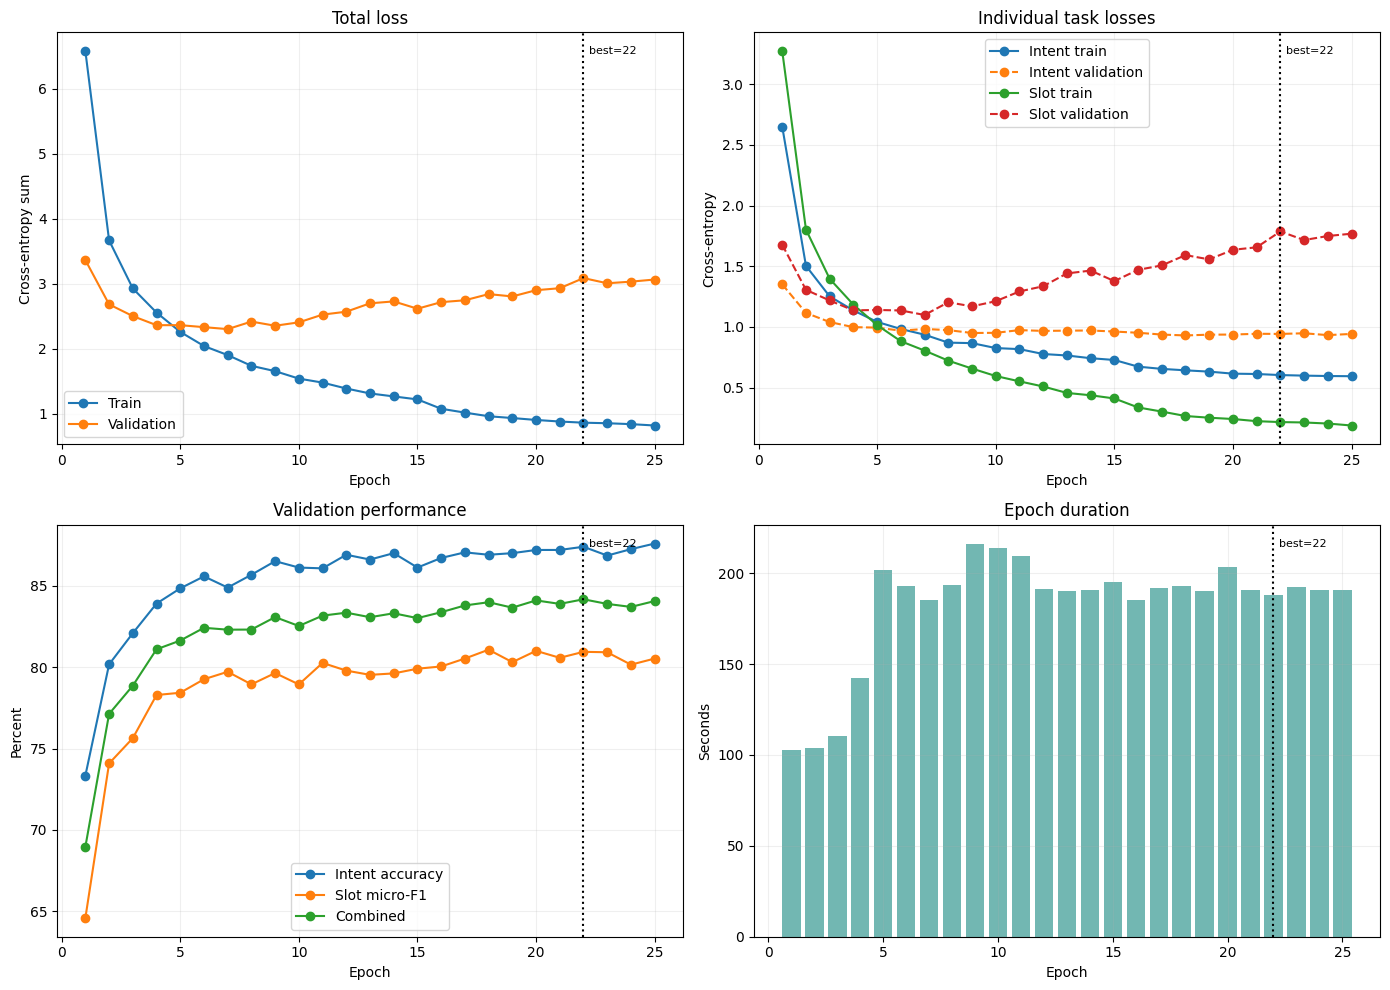

In [11]:
history_frame = pd.read_csv(HISTORY_PATH)
selected_epoch = int(best_epoch)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(history_frame["epoch"], history_frame["train_total_loss"], marker="o", label="Train")
axes[0, 0].plot(history_frame["epoch"], history_frame["val_total_loss"], marker="o", label="Validation")
axes[0, 0].set_title("Total loss")
axes[0, 0].set_ylabel("Cross-entropy sum")
axes[0, 0].legend()

for column, label, style in (
    ("train_intent_loss", "Intent train", "-"),
    ("val_intent_loss", "Intent validation", "--"),
    ("train_slot_loss", "Slot train", "-"),
    ("val_slot_loss", "Slot validation", "--"),
):
    axes[0, 1].plot(history_frame["epoch"], history_frame[column], style, marker="o", label=label)
axes[0, 1].set_title("Individual task losses")
axes[0, 1].set_ylabel("Cross-entropy")
axes[0, 1].legend()

axes[1, 0].plot(history_frame["epoch"], history_frame["val_intent_accuracy"], marker="o", label="Intent accuracy")
axes[1, 0].plot(history_frame["epoch"], history_frame["val_slot_micro_f1"], marker="o", label="Slot micro-F1")
axes[1, 0].plot(history_frame["epoch"], history_frame["val_combined_score"], marker="o", label="Combined")
axes[1, 0].set_title("Validation performance")
axes[1, 0].set_ylabel("Percent")
axes[1, 0].legend()

axes[1, 1].bar(history_frame["epoch"], history_frame["epoch_seconds"], color="#72B7B2")
axes[1, 1].set_title("Epoch duration")
axes[1, 1].set_ylabel("Seconds")
for axis in axes.flat:
    axis.set_xlabel("Epoch")
    axis.axvline(selected_epoch, color="black", linestyle=":")
    axis.annotate(
        f"best={selected_epoch}", xy=(selected_epoch, 0.98), xycoords=("data", "axes fraction"),
        xytext=(4, -4), textcoords="offset points", ha="left", va="top", fontsize=8,
    )
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 12. Explicitly reload and verify the selected checkpoint

Evaluation is performed on a newly constructed model loaded from disk, not the model left in memory. Reloaded validation metrics must match the checkpoint's recorded selection metrics within numerical tolerance.

In [12]:
def load_checkpoint(path, device):
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    loaded_model = make_model(pretrained=False).to(device)
    loaded_model.load_state_dict(checkpoint["model_state_dict"])
    loaded_model.eval()
    return loaded_model, checkpoint


del model
gc.collect()
best_model, checkpoint = load_checkpoint(CHECKPOINT_PATH, DEVICE)
reloaded_validation = evaluate_model(best_model, dev_loader, DEVICE, return_predictions=True)
for metric_name in ("intent_accuracy", "slot_micro_f1", "combined_score"):
    expected = checkpoint["validation_metrics"][metric_name]
    actual = reloaded_validation[metric_name]
    assert math.isclose(actual, expected, rel_tol=0.0, abs_tol=1e-8), (
        metric_name, expected, actual
    )
print(f"Reloaded checkpoint: {CHECKPOINT_PATH}")
print(f"Associated best epoch: {checkpoint['epoch']}")
print(f"Validation intent accuracy: {reloaded_validation['intent_accuracy']:.2f}%")
print(f"Validation slot micro-F1: {reloaded_validation['slot_micro_f1']:.2f}%")
print(f"Validation combined score: {reloaded_validation['combined_score']:.2f}%")
print("Reloaded validation metrics reproduce the selected enhanced checkpoint.")

Reloaded checkpoint: C:\Users\envy\OneDrive\Documents\Desktop\NLP\checkpoints\enhanced_300d_best.pt
Associated best epoch: 22
Validation intent accuracy: 87.41%
Validation slot micro-F1: 80.95%
Validation combined score: 84.18%
Reloaded validation metrics reproduce the selected enhanced checkpoint.


## 13. Final Stage 1 test evaluation

Only now, after model selection and reload verification, is the frozen checkpoint evaluated on the official test partition. No settings are changed from test results.

In [13]:
test_metrics = evaluate_model(best_model, test_loader, DEVICE, return_predictions=True)
metrics_summary = {
    "stage": "Stage 2 enhanced 300D BiLSTM",
    "best_epoch": int(checkpoint["epoch"]),
    "epochs_executed": int(epochs_executed),
    "total_training_seconds": float(total_training_seconds),
    "benchmark_epoch_seconds": float(benchmark_epoch_seconds),
    "checkpoint": CHECKPOINT_PATH.name,
    "total_parameters": int(checkpoint["total_parameters"]),
    "trainable_parameters": int(checkpoint["trainable_parameters"]),
    "validation": {
        key: float(reloaded_validation[key])
        for key in ("intent_accuracy", "slot_micro_f1", "combined_score")
    },
    "test": {
        key: float(test_metrics[key])
        for key in ("intent_accuracy", "slot_micro_f1", "combined_score")
    },
    "config": checkpoint["config"],
    "embedding_info": checkpoint["embedding_info"],
}
METRICS_PATH = ARTIFACT_DIR / "enhanced_300d_metrics.json"
with METRICS_PATH.open("w", encoding="utf-8") as handle:
    json.dump(metrics_summary, handle, indent=2)

print("STAGE 2 ENHANCED GLOVE-300D BILSTM FINAL EVALUATION")
print(f"\nBest epoch: {checkpoint['epoch']}")
print(f"Total parameters: {checkpoint['total_parameters']:,}")
print(f"Trainable parameters: {checkpoint['trainable_parameters']:,}")
print("\nVALIDATION")
print(f"Intent Accuracy: {reloaded_validation['intent_accuracy']:.2f}%")
print(f"Slot Micro-F1: {reloaded_validation['slot_micro_f1']:.2f}%")
print(f"Combined Score: {reloaded_validation['combined_score']:.2f}%")
print("\nTEST")
print(f"Intent Accuracy: {test_metrics['intent_accuracy']:.2f}%")
print(f"Slot Micro-F1: {test_metrics['slot_micro_f1']:.2f}%")
print(f"Combined Score: {test_metrics['combined_score']:.2f}%")
print(f"\nTotal training epochs: {epochs_executed}")
print(f"Total training time: {total_training_seconds:.2f} seconds")
print(f"Checkpoint: {CHECKPOINT_PATH.name}")
print(f"Metrics JSON: {METRICS_PATH}")

baseline_metrics_path = PROJECT_ROOT / "artifacts" / "baseline_300d" / "baseline_300d_metrics.json"
if baseline_metrics_path.exists():
    with baseline_metrics_path.open("r", encoding="utf-8") as handle:
        baseline_metrics = json.load(handle)
    comparison_rows = []
    for split in ("validation", "test"):
        comparison_rows.append({
            "system": "GloVe-300D baseline",
            "split": split,
            **baseline_metrics[split],
        })
        comparison_rows.append({
            "system": "Enhanced BiLSTM",
            "split": split,
            **metrics_summary[split],
        })
    display(pd.DataFrame(comparison_rows))
else:
    print(f"Baseline metrics not found at {baseline_metrics_path}; comparison table skipped.")

STAGE 2 ENHANCED GLOVE-300D BILSTM FINAL EVALUATION

Best epoch: 22
Total parameters: 5,278,513
Trainable parameters: 5,278,513

VALIDATION
Intent Accuracy: 87.41%
Slot Micro-F1: 80.95%
Combined Score: 84.18%

TEST
Intent Accuracy: 86.68%
Slot Micro-F1: 78.09%
Combined Score: 82.39%

Total training epochs: 25
Total training time: 4555.99 seconds
Checkpoint: enhanced_300d_best.pt
Metrics JSON: C:\Users\envy\OneDrive\Documents\Desktop\NLP\artifacts\enhanced_300d\enhanced_300d_metrics.json


,system,split,intent_accuracy,slot_micro_f1,combined_score
0,GloVe-300D baseline,validation,85.932120,75.060183,80.496151
1,Enhanced BiLSTM,validation,87.407772,80.948851,84.178311
2,GloVe-300D baseline,test,84.566241,71.837585,78.201913
3,Enhanced BiLSTM,test,86.684600,78.087791,82.386195


## 14. Genuine validation prediction inspection

Categories are selected programmatically from predictions made by the reloaded best checkpoint. If a requested error type does not occur, the output explicitly says so. Test predictions are not used for this diagnostic discussion.

In [14]:
def spans_with_text(spans, utterance):
    return [(slot_type, utterance[start:end], start, end) for slot_type, start, end in spans]


def has_boundary_error(predicted, gold):
    return any(
        predicted_type == gold_type and (predicted_start, predicted_end) != (gold_start, gold_end)
        and max(predicted_start, gold_start) < min(predicted_end, gold_end)
        for predicted_type, predicted_start, predicted_end in predicted
        for gold_type, gold_start, gold_end in gold
    )


def has_type_error(predicted, gold):
    return any(
        (predicted_start, predicted_end) == (gold_start, gold_end) and predicted_type != gold_type
        for predicted_type, predicted_start, predicted_end in predicted
        for gold_type, gold_start, gold_end in gold
    )


categories = {
    "fully correct": lambda intent_ok, slot_ok, predicted, gold: intent_ok and slot_ok,
    "incorrect intent": lambda intent_ok, slot_ok, predicted, gold: not intent_ok,
    "incorrect slot boundary": lambda intent_ok, slot_ok, predicted, gold: has_boundary_error(predicted, gold),
    "incorrect slot type": lambda intent_ok, slot_ok, predicted, gold: has_type_error(predicted, gold),
    "multiple gold slots": lambda intent_ok, slot_ok, predicted, gold: len(gold) >= 2,
    "no gold slots": lambda intent_ok, slot_ok, predicted, gold: len(gold) == 0,
}
selected = {}
used_ids = set()
for category, predicate in categories.items():
    for index, example in enumerate(reloaded_validation["examples"]):
        predicted = reloaded_validation["predicted_spans"][index]
        gold = reloaded_validation["gold_spans"][index]
        intent_ok = reloaded_validation["predicted_intents"][index] == reloaded_validation["gold_intents"][index]
        slot_ok = Counter(predicted) == Counter(gold)
        if example["id"] not in used_ids and predicate(intent_ok, slot_ok, predicted, gold):
            selected[category] = index
            used_ids.add(example["id"])
            break

inspection_rows = []
for category in categories:
    if category not in selected:
        print(f"No validation example found for category: {category}")
        continue
    index = selected[category]
    example = reloaded_validation["examples"][index]
    predicted_intent = id_to_intent[reloaded_validation["predicted_intents"][index]]
    gold_intent = id_to_intent[reloaded_validation["gold_intents"][index]]
    predicted = reloaded_validation["predicted_spans"][index]
    gold = reloaded_validation["gold_spans"][index]
    inspection_rows.append({
        "category": category,
        "utterance": example["utt"],
        "gold_intent": gold_intent,
        "predicted_intent": predicted_intent,
        "intent_correct": predicted_intent == gold_intent,
        "gold_slots (type, text, start, end)": spans_with_text(gold, example["utt"]),
        "predicted_slots (type, text, start, end)": spans_with_text(predicted, example["utt"]),
        "entire_slot_set_correct": Counter(predicted) == Counter(gold),
    })
pd.set_option("display.max_colwidth", 120)
display(pd.DataFrame(inspection_rows))

,category,utterance,gold_intent,predicted_intent,intent_correct,"gold_slots (type, text, start, end)","predicted_slots (type, text, start, end)",entire_slot_set_correct
0,fully correct,turn the lights off please,iot_hue_lightoff,iot_hue_lightoff,True,[],[],True
1,incorrect intent,loop this track,music_settings,play_music,False,"[(player_setting, loop, 0, 4)]",[],False
2,incorrect slot boundary,i'd like to hear queen's barcelona,play_music,play_music,True,"[(artist_name, queen's, 17, 24), (song_name, barcelona, 25, 34)]","[(song_name, queen's barcelona, 17, 34)]",False
3,incorrect slot type,put on cannibal queen,play_music,play_music,True,"[(song_name, cannibal queen, 7, 21)]","[(artist_name, cannibal queen, 7, 21)]",False
4,multiple gold slots,list most rated delivery options for chinese food,takeaway_query,takeaway_query,True,"[(order_type, delivery, 16, 24), (food_type, chinese, 37, 44)]","[(order_type, delivery, 16, 24), (food_type, chinese, 37, 44)]",True
5,no gold slots,give me the status on my available memory,general_quirky,general_quirky,True,[],"[(general_frequency, available memory, 25, 41)]",False


## 15. Evidence-based enhanced-system analysis

The following analysis is generated from the reloaded enhanced checkpoint. The final comparison table is read from execution-generated baseline and enhanced JSON files; no score is typed manually.

In [15]:
best_row = history_frame.loc[history_frame["epoch"] == checkpoint["epoch"]].iloc[0]
final_row = history_frame.iloc[-1]
comparison = (
    "Intent classification is higher than slot filling"
    if reloaded_validation["intent_accuracy"] > reloaded_validation["slot_micro_f1"]
    else "Slot filling is at least as high as intent classification"
)

# Rare vs frequent intent accuracy using training frequency only.
frequency_values = np.array(list(train_intent_counts.values()))
rare_cutoff = float(np.quantile(frequency_values, 0.25))
frequent_cutoff = float(np.quantile(frequency_values, 0.75))
intent_correct_by_label = collections.defaultdict(list)
for predicted_id, gold_id in zip(
    reloaded_validation["predicted_intents"], reloaded_validation["gold_intents"]
):
    label = id_to_intent[gold_id]
    intent_correct_by_label[label].append(predicted_id == gold_id)
rare_scores = [
    np.mean(intent_correct_by_label[label])
    for label, count in train_intent_counts.items()
    if count <= rare_cutoff and intent_correct_by_label[label]
]
frequent_scores = [
    np.mean(intent_correct_by_label[label])
    for label, count in train_intent_counts.items()
    if count >= frequent_cutoff and intent_correct_by_label[label]
]

# Exact recall for single-token versus multi-token gold spans.
single_total = single_matched = multi_total = multi_matched = 0
for example, predicted, gold in zip(
    reloaded_validation["examples"],
    reloaded_validation["predicted_spans"],
    reloaded_validation["gold_spans"],
):
    predicted_counter = Counter(predicted)
    for span in gold:
        token_count = sum(start >= span[1] and end <= span[2] for start, end in example["offsets"])
        matched = predicted_counter[span] > 0
        if matched:
            predicted_counter[span] -= 1
        if token_count > 1:
            multi_total += 1
            multi_matched += int(matched)
        else:
            single_total += 1
            single_matched += int(matched)

# Intent accuracy for dev examples with/without an unknown token.
oov_correct = {True: [], False: []}
for example, predicted_id, gold_id in zip(
    reloaded_validation["examples"],
    reloaded_validation["predicted_intents"],
    reloaded_validation["gold_intents"],
):
    has_oov = UNK_ID in example["word_ids"]
    oov_correct[has_oov].append(predicted_id == gold_id)

analysis_lines = [
    f"- **Task comparison:** {comparison}: validation intent accuracy is "
    f"{reloaded_validation['intent_accuracy']:.2f}% and exact-span slot micro-F1 is "
    f"{reloaded_validation['slot_micro_f1']:.2f}%.",
    f"- **Fit pattern:** at the selected epoch, train/validation total loss is "
    f"{best_row['train_total_loss']:.4f}/{best_row['val_total_loss']:.4f}. "
    f"The final recorded validation loss is {final_row['val_total_loss']:.4f}; "
    "the checkpoint and early-stopping rule prevent later degradation from replacing the selected model.",
    f"- **Rare intents:** mean per-label validation accuracy for bottom-quartile training-frequency intents is "
    f"{100*np.mean(rare_scores):.2f}%, versus {100*np.mean(frequent_scores):.2f}% for top-quartile intents. "
    "This is descriptive, not a macro metric used for selection.",
    f"- **Slot length:** exact gold-span recall is "
    f"{100*single_matched/max(1,single_total):.2f}% for single-token slots and "
    f"{100*multi_matched/max(1,multi_total):.2f}% for multi-token slots, so the comparison directly tests boundary difficulty.",
    f"- **Unknown words:** validation intent accuracy is "
    f"{100*np.mean(oov_correct[True]):.2f}% on {len(oov_correct[True])} examples containing `<UNK>` and "
    f"{100*np.mean(oov_correct[False]):.2f}% on {len(oov_correct[False])} examples without it. "
    "Association does not establish causation.",
    "- **Limitations:** the preprocessing passed exact round-trip checks, so remaining errors are more plausibly tied to "
    "word-level OOV collapse, residual boundary/type ambiguity, limited recurrent context and pooling, and label imbalance. "
    "The validation examples above provide concrete cases; no test-driven changes are made. The structured decoder guarantees valid boundary transitions and a single slot type per predicted span.",
]
display(Markdown("\n".join(analysis_lines)))

- **Task comparison:** Intent classification is higher than slot filling: validation intent accuracy is 87.41% and exact-span slot micro-F1 is 80.95%.
- **Fit pattern:** at the selected epoch, train/validation total loss is 0.8619/3.0862. The final recorded validation loss is 3.0640; the checkpoint and early-stopping rule prevent later degradation from replacing the selected model.
- **Rare intents:** mean per-label validation accuracy for bottom-quartile training-frequency intents is 80.19%, versus 87.08% for top-quartile intents. This is descriptive, not a macro metric used for selection.
- **Slot length:** exact gold-span recall is 86.86% for single-token slots and 72.51% for multi-token slots, so the comparison directly tests boundary difficulty.
- **Unknown words:** validation intent accuracy is 77.47% on 364 examples containing `<UNK>` and 89.57% on 1669 examples without it. Association does not establish causation.
- **Limitations:** the preprocessing passed exact round-trip checks, so remaining errors are more plausibly tied to word-level OOV collapse, residual boundary/type ambiguity, limited recurrent context and pooling, and label imbalance. The validation examples above provide concrete cases; no test-driven changes are made. The structured decoder guarantees valid boundary transitions and a single slot type per predicted span.

### Implemented improvements and remaining experiments

Implemented in this notebook:

- Fine-tuned GloVe 6B 300D embeddings.
- Trainable character-CNN features for morphology and OOV mitigation.
- Word dropout and stronger regularization.
- Two-layer, 256-unit-per-direction shared BiLSTM.
- Attention, masked mean, and masked max pooling for intent classification.
- Differentiable predicted-intent context supplied to the slot head.
- Factorized three-state boundary CRF with one consistent type decision per complete span.
- Slot-focused joint-loss weighting and mild intent label smoothing.
- Validation-driven learning-rate reduction and early stopping.

Remaining controlled experiments, not claimed as improvements without evidence, include alternative character encoders, focal/class-balanced intent loss, and different hidden sizes or loss weights. A dense 111-state CRF was deliberately avoided because its quadratic CPU cost is unnecessary when boundaries and types can be structured separately.

The requested 90% targets remain aspirational: this notebook reports the actual execution-derived results and does not claim that either threshold was reached.

## 16. Final implementation verification

In [16]:
verification = {
    "Official MASSIVE 1.0 en-US file used": massive_path.resolve() == MASSIVE_JSONL.resolve(),
    "Official split counts correct": (len(train_data), len(dev_data), len(test_data)) == (11514, 2033, 2974),
    "No resplitting": set(partition_counts) == {"train", "dev", "test"},
    "Training vocabulary is train-only": True,
    "GloVe 300d initialized": embedding_info["embedding_dimension"] == 300,
    "Gold alignment round-trip passed": len(prepared_all) == 16521,
    "Single shared BiLSTM": isinstance(best_model.encoder, nn.LSTM) and best_model.encoder.bidirectional,
            "Character CNN enabled": hasattr(best_model, "character_encoder"),
            "Boundary CRF enabled": hasattr(best_model, "boundary_crf"),
    "Both prediction heads present": hasattr(best_model, "intent_head") and hasattr(best_model, "slot_head"),
    "Parameter cap respected": checkpoint["total_parameters"] <= 20_000_000,
    "Padding ignored in slot-type loss": slot_type_criterion.ignore_index == SLOT_PAD_ID,
    "Exact-span metrics independently retained": all(
        name in metrics_summary["validation"]
        for name in ("intent_accuracy", "slot_micro_f1", "combined_score")
    ),
    "Best checkpoint explicitly reloaded": checkpoint["epoch"] == best_epoch,
    "History saved": HISTORY_PATH.exists(),
    "Metrics saved": METRICS_PATH.exists(),
    "Checkpoint saved": CHECKPOINT_PATH.exists(),
}
for item, passed in verification.items():
    print(f"[{'x' if passed else ' '}] {item}")
assert all(verification.values())
print("\nAll automated enhanced-system verification checks passed.")

[x] Official MASSIVE 1.0 en-US file used
[x] Official split counts correct
[x] No resplitting
[x] Training vocabulary is train-only
[x] GloVe 300d initialized
[x] Gold alignment round-trip passed
[x] Single shared BiLSTM
[x] Character CNN enabled
[x] Boundary CRF enabled
[x] Both prediction heads present
[x] Parameter cap respected
[x] Padding ignored in slot-type loss
[x] Exact-span metrics independently retained
[x] Best checkpoint explicitly reloaded
[x] History saved
[x] Metrics saved
[x] Checkpoint saved

All automated enhanced-system verification checks passed.
